# Evidential uncertainty on your own dataset
This guide trains a CPU evidential model, chooses its checkpoint using validation data, and evaluates the untouched test set. Its default uses the authors’ bundled Cabauw dataset, original PyTorch regression architecture and one-pass training settings. To use your own CSV, edit the next configuration cell: choose regression or classification, specify the input and target columns, and choose an appropriate split. The classification option requires your labeled CSV and starts from the authors’ PyTorch classifier configuration. The restored original notebooks remain the reference for reproducing each authors’ experiment.

For regression, the network predicts Normal–Inverse–Gamma parameters and a Student-t predictive distribution. For classification, it predicts evidence defining a Dirichlet distribution. Aleatoric and epistemic outputs are variances. They are not interchangeable with predictive interval widths or Dempster–Shafer uncertainty mass.

**Research use:** split independent experimental units before preprocessing. For repeated subjects, trajectories, stations or simulations, use group splitting. For forecasting, use chronological splitting. Keep the test set separate from model selection; if you tune based on its results, it becomes validation data and you need a new test set.

The default follows the authors’ bundled data and notebook settings. Assess performance separately on your own held-out data.

## 1. Configure your data

In [1]:
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/"config/evidential_regression_torch.yml").is_file()), None)
if ROOT is None: raise FileNotFoundError("Start Jupyter from this unpacked repository")
TASK = "regression"               # "regression" or "classification"
DATA_PATH = None                  # None: authors' bundled Cabauw CSV; otherwise your CSV
FEATURE_COLUMNS = None           # REQUIRED for your CSV, e.g. ["x1", "x2"]
TARGET_COLUMNS = None            # regression: ["y1", "y2"]; classification: ["label"]
SPLIT_STRATEGY = "group"         # your CSV: "random", "group", or "time"
GROUP_COLUMN = "year"           # your grouping column; default sample uses original year split
TIME_COLUMN = None              # only required for a chronological split
PLOT_TIME_COLUMN = None         # independent of split: default Cabauw Time, else TIME_COLUMN
PLOT_TIME_WINDOW = None         # Cabauw default: first 7 days; your CSV: all times; e.g. "7D"
SEED = 1000
TEST_FRACTION = 0.10
VALIDATION_FRACTION = 0.1035      # original regression: 0.9 * (1 - 0.885)
EPOCHS = None                    # original notebook: regression 1, classification 100
BATCH_SIZE = None                # original notebook: regression 128, classification 1024
MAX_BATCHES = None               # original: all regression batches; 10 classification batches
PATIENCE = None                  # no shortened training budget by default
LEARNING_RATE = 0.001            # original notebook Adam rate
OUTPUT_DIR = Path("outputs/custom_dataset_guide")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Imports and reproducibility

In [2]:
import copy
import yaml
import json
import platform
from importlib.metadata import version
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import RobustScaler, MinMaxScaler, LabelEncoder

from mlguess.torch.models import DNN, CategoricalDNN, seed_everything
from mlguess.torch.regression_losses import LipschitzMSELoss
from mlguess.torch.class_losses import EDLDigammaLoss
from mlguess.evaluation import evaluate_nig, evaluate_classifier

seed_everything(SEED)
torch.set_num_threads(2)
device = torch.device("cpu")
print({"python": platform.python_version(), "torch": torch.__version__,
       "numpy": np.__version__, "device": str(device)})
config_path = ROOT/"config"/("evidential_regression_torch.yml" if TASK == "regression"
                              else "evidential_classifier_torch.yml")
with config_path.open() as stream:
    author_config = yaml.safe_load(stream)
EPOCHS = (1 if TASK == "regression" else 100) if EPOCHS is None else EPOCHS
BATCH_SIZE = (128 if TASK == "regression" else 1024) if BATCH_SIZE is None else BATCH_SIZE
MAX_BATCHES = (0 if TASK == "regression" else 10) if MAX_BATCHES is None else MAX_BATCHES
print("Starting configuration:", config_path.relative_to(ROOT),
      "epochs:", EPOCHS, "batch size:", BATCH_SIZE, "maximum batches:", MAX_BATCHES)


{'python': '3.11.17', 'torch': '2.14.1+cpu', 'numpy': '2.4.6', 'device': 'cpu'}
Starting configuration: config/evidential_regression_torch.yml epochs: 1 batch size: 128 maximum batches: 0


## 3. Load the authors' sample or your CSV
The default is the unmodified `data/sample_cabauw_surface_layer.csv`, not generated data. Its original input columns and friction-velocity target come from the authors' YAML. The default regression split and scalers also match the original PyTorch notebook.

For your data, set `DATA_PATH`, column lists, and split settings explicitly. Only numeric features are supported here; fit any categorical encoder or missing-data imputer on training data only. Do not include target-derived variables or identifiers as features.

Use `PLOT_TIME_COLUMN` for an observation date/time even when splitting by group or randomly. It is metadata, never automatically a feature or a split rule. The default Cabauw plot shows its first seven held-out days; set a different positive duration (for example `"30D"`) to change the view. For your CSV, `None` shows all held-out times. Numeric time coordinates retain the source units; a numeric window uses those same units. Invalid or missing times in a specified column raise a clear error. Without a time column, intervals are plotted against the predicted target value.

Naive source timestamps retain their original timezone-unspecified meaning. Explicit timezone offsets are converted to UTC for plotting. Mixed timezone-naive and timezone-aware values must be normalized explicitly before use.


In [3]:
def parse_plot_times(frame, column):
    """Read plotting coordinates without altering row order, features, or splitting."""
    if column is None:
        return None
    if column not in frame:
        raise ValueError(f"Plot time column {column!r} is absent from the CSV")
    values = frame[column]
    if pd.api.types.is_numeric_dtype(values):
        times = pd.to_numeric(values, errors="coerce")
        invalid = ~np.isfinite(times.to_numpy(dtype=float))
    else:
        parsed = [pd.to_datetime(value, errors="coerce", format="mixed") for value in values]
        aware = {value.tzinfo is not None for value in parsed if not pd.isna(value)}
        if len(aware) > 1:
            raise ValueError(f"Plot time column {column!r} mixes timezone-naive and timezone-aware values; normalize them explicitly first")
        # Never invent a timezone for source timestamps whose timezone is unstated.
        times = pd.Series(pd.to_datetime(parsed, utc=aware == {True}), index=values.index, name=values.name)
        invalid = times.isna().to_numpy()
    if invalid.any():
        rows = np.flatnonzero(invalid)[:5].tolist()
        raise ValueError(f"Plot time column {column!r} contains missing or invalid times at row positions {rows}")
    return times


def prediction_display(predicted, times=None, window=None):
    """Return positions into predictions and meaningful x coordinates for display."""
    if times is None:
        order = np.argsort(predicted, kind="stable")
        return order, np.asarray(predicted)[order]
    times = times.reset_index(drop=True)
    order = np.argsort(times.to_numpy(), kind="stable")
    if window is not None:
        if pd.api.types.is_numeric_dtype(times):
            if isinstance(window, bool) or not isinstance(window, (int, float)) or not np.isfinite(window) or window <= 0:
                raise ValueError("For numeric times, PLOT_TIME_WINDOW must be a positive number in the source time units")
            duration = window
        else:
            try:
                duration = pd.Timedelta(window)
            except (TypeError, ValueError) as exc:
                raise ValueError("For date/time values, PLOT_TIME_WINDOW must be a duration such as '7D'") from exc
            if pd.isna(duration) or duration <= pd.Timedelta(0):
                raise ValueError("PLOT_TIME_WINDOW must be a positive duration")
        order = order[(times.iloc[order] < times.iloc[order[0]] + duration).to_numpy()]
    return order, times.iloc[order]

if TASK not in {"regression", "classification"}:
    raise ValueError("TASK must be regression or classification")
USING_AUTHORS_SAMPLE = DATA_PATH is None
if USING_AUTHORS_SAMPLE:
    if TASK != "regression":
        raise ValueError("For classification, provide your labeled CSV and its columns; see classifier_example_torch.ipynb for the authors' precipitation workflow")
    DATA_PATH = ROOT/"data/sample_cabauw_surface_layer.csv"
    frame = pd.read_csv(DATA_PATH)
    frame["year"] = frame["Time"].astype(str).str.split("-").str[0]
    FEATURE_COLUMNS = list(author_config["data"]["input_cols"])
    TARGET_COLUMNS = list(author_config["data"]["output_cols"])
else:
    frame = pd.read_csv(DATA_PATH)
    if not FEATURE_COLUMNS or not TARGET_COLUMNS:
        raise ValueError("Set FEATURE_COLUMNS and TARGET_COLUMNS explicitly for your CSV")
print("Data:", Path(DATA_PATH).resolve(), "rows:", len(frame))

if set(FEATURE_COLUMNS) & set(TARGET_COLUMNS):
    raise ValueError("Input and target columns must be disjoint")
if TASK == "classification" and len(TARGET_COLUMNS) != 1:
    raise ValueError("Classification requires exactly one target column")
if len(frame) < 30:
    raise ValueError("This three-way demonstration requires at least 30 rows")
if frame[FEATURE_COLUMNS + TARGET_COLUMNS].isna().any().any():
    raise ValueError("Missing data detected. Define an imputation policy fitted on TRAINING data only.")
X_all = frame[FEATURE_COLUMNS].apply(pd.to_numeric, errors="raise").to_numpy(dtype=np.float64)
if not np.isfinite(X_all).all():
    raise ValueError("Input features must be finite numeric values")
if TASK == "regression":
    y_all = frame[TARGET_COLUMNS].apply(pd.to_numeric, errors="raise").to_numpy(dtype=np.float64)
    if not np.isfinite(y_all).all(): raise ValueError("Targets must be finite")
else:
    # Convert labels consistently, e.g. string class names.
    y_all = frame[TARGET_COLUMNS[0]].astype(str).to_numpy()
display(frame.head())
plot_time_column = PLOT_TIME_COLUMN or ("Time" if USING_AUTHORS_SAMPLE else TIME_COLUMN)
plot_times = parse_plot_times(frame, plot_time_column)
plot_time_window = PLOT_TIME_WINDOW if PLOT_TIME_WINDOW is not None else ("7D" if USING_AUTHORS_SAMPLE else None)


Data: /workspace/scratch/d7d34632ac75/miles-guess/data/sample_cabauw_surface_layer.csv rows: 72197


,Unnamed: 0,Time,wind_speed:10_m:m_s-1,potential_temperature_skin_change:10_m:K_m-1,bulk_richardson:10_m:None,mixing_ratio_skin_change:2_m:g_kg-1_m-1,friction_velocity:surface:m_s-1,year
0,524065,2013-05-10 10:00:00,9.276667,-0.158203,-0.001387,-0.035977,0.508374,2013
1,232299,2007-09-14 19:00:00,1.640000,0.205809,0.435410,-0.012684,0.100056,2007
2,716146,2017-03-02 19:30:00,6.293333,0.251677,0.029591,-0.071556,0.365158,2017
3,398741,2010-12-01 00:20:00,6.413333,0.098486,0.011619,-0.075662,0.410288,2010
4,276684,2008-07-22 23:00:00,1.303333,0.001096,0.348421,-0.026073,0.055734,2008


## 4. Split before fitting preprocessing
Group fractions operate on groups, so row proportions may differ. Chronological splits keep equal timestamps together. These mechanisms do not replace a domain-specific leakage review.

In [4]:
def split_rows(frame, task, strategy, labels, test_fraction, validation_fraction,
               seed, group_column=None, time_column=None):
    if not (0 < test_fraction < 1 and 0 < validation_fraction < 1
            and test_fraction + validation_fraction < 1):
        raise ValueError("Choose positive test/validation fractions with sum below one")
    rows = np.arange(len(frame))
    if strategy == "random":
        stratify = labels if task == "classification" else None
        train_val, test = train_test_split(rows, test_size=test_fraction,
                                           random_state=seed, stratify=stratify)
        stratify_tv = labels[train_val] if task == "classification" else None
        train, validation = train_test_split(train_val,
            test_size=validation_fraction/(1-test_fraction),
            random_state=seed+1, stratify=stratify_tv)
    elif strategy == "group":
        if group_column is None or frame[group_column].isna().any():
            raise ValueError("Provide a complete GROUP_COLUMN")
        groups = frame[group_column].to_numpy()
        train_val, test = next(GroupShuffleSplit(n_splits=1, test_size=test_fraction,
            random_state=seed).split(rows, groups=groups))
        tr, va = next(GroupShuffleSplit(n_splits=1,
            test_size=validation_fraction/(1-test_fraction), random_state=seed+1)
            .split(train_val, groups=groups[train_val]))
        train, validation = train_val[tr], train_val[va]
        assert not (set(groups[train]) & set(groups[test]))
        assert not (set(groups[train]) & set(groups[validation]))
        assert not (set(groups[validation]) & set(groups[test]))
    elif strategy == "time":
        if time_column is None or frame[time_column].isna().any():
            raise ValueError("Provide a complete TIME_COLUMN")
        times = frame[time_column]
        if not pd.api.types.is_numeric_dtype(times):
            times = pd.to_datetime(times, errors="raise", utc=True)
        # Whole equal-time blocks stay in one subset; no same-time leakage.
        unique_times = np.sort(times.unique())
        if len(unique_times) < 5: raise ValueError("Need at least five distinct times")
        cut1 = max(1, int(len(unique_times)*(1-test_fraction-validation_fraction)))
        cut2 = max(cut1+1, int(len(unique_times)*(1-test_fraction)))
        cut2 = min(cut2, len(unique_times)-1)
        train = rows[times.isin(unique_times[:cut1])]
        validation = rows[times.isin(unique_times[cut1:cut2])]
        test = rows[times.isin(unique_times[cut2:])]
    else:
        raise ValueError("Unknown split strategy")
    assert set(train).isdisjoint(validation) and set(train).isdisjoint(test)
    assert set(validation).isdisjoint(test)
    assert len(train)+len(validation)+len(test) == len(frame)
    return train, validation, test

if USING_AUTHORS_SAMPLE:
    # Exact original two-stage group split: seed 1000 for both, split index 0.
    outer = GroupShuffleSplit(n_splits=1, random_state=1000, train_size=0.9)
    train_val_idx, test_idx = next(outer.split(frame, groups=frame["year"]))
    inner = GroupShuffleSplit(n_splits=1, random_state=1000, train_size=0.885)
    tr, va = next(inner.split(frame.iloc[train_val_idx], groups=frame.iloc[train_val_idx]["year"]))
    train_idx, val_idx = train_val_idx[tr], train_val_idx[va]
else:
    train_idx, val_idx, test_idx = split_rows(frame, TASK, SPLIT_STRATEGY, y_all,
        TEST_FRACTION, VALIDATION_FRACTION, SEED, GROUP_COLUMN, TIME_COLUMN)
split_labels = np.empty(len(frame), dtype=object)
split_labels[train_idx], split_labels[val_idx], split_labels[test_idx] = "train", "validation", "test"
pd.DataFrame({"row_position": np.arange(len(frame)), "split": split_labels}).to_csv(
    OUTPUT_DIR/"split_assignments.csv", index=False)
display(pd.Series(split_labels).value_counts().rename("rows").to_frame())

,rows
train,55007
test,10592
validation,6598


## 5. Fit preprocessing on training rows only

In [5]:
x_scaler = RobustScaler().fit(X_all[train_idx])
X_train = torch.tensor(x_scaler.transform(X_all[train_idx]), dtype=torch.float32, device=device)
X_val = torch.tensor(x_scaler.transform(X_all[val_idx]), dtype=torch.float32, device=device)
# Test transformation uses the same TRAIN-fitted scaler.
X_test = torch.tensor(x_scaler.transform(X_all[test_idx]), dtype=torch.float32, device=device)

y_scaler, label_encoder = None, None
if TASK == "regression":
    y_scaler = MinMaxScaler((0, 1)).fit(y_all[train_idx])
    Y_train = torch.tensor(y_scaler.transform(y_all[train_idx]), dtype=torch.float32)
    Y_val = torch.tensor(y_scaler.transform(y_all[val_idx]), dtype=torch.float32)
    model_kwargs = copy.deepcopy(author_config["model"])
    model_kwargs.update(input_size=X_train.shape[1], output_size=Y_train.shape[1], lng=True)
    model = DNN(**model_kwargs).to(device)
    criterion = LipschitzMSELoss(**author_config["train_loss"])
else:
    label_encoder = LabelEncoder().fit(y_all[train_idx])
    unseen = set(y_all[val_idx]) | set(y_all[test_idx])
    unseen -= set(label_encoder.classes_)
    if unseen:
        raise ValueError(f"Classes absent from training data: {unseen}. Reconsider the split.")
    n_classes = len(label_encoder.classes_)
    if n_classes < 2: raise ValueError("Need at least two training classes")
    Y_train = torch.nn.functional.one_hot(
        torch.tensor(label_encoder.transform(y_all[train_idx])), n_classes).float()
    Y_val = torch.nn.functional.one_hot(
        torch.tensor(label_encoder.transform(y_all[val_idx])), n_classes).float()
    model_kwargs = copy.deepcopy(author_config["model"])
    model_kwargs.update(input_size=X_train.shape[1], output_size=n_classes, softmax=False, lng=False)
    model = CategoricalDNN(**model_kwargs).to(device)
    criterion = EDLDigammaLoss(num_classes=n_classes, annealing_step=10)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model.__class__.__name__, "inputs:", X_train.shape[1], "targets/classes:", model_kwargs["output_size"])

DNN inputs: 4 targets/classes: 1


## 6. Train and select using validation NLL
The regularized training objective and validation predictive NLL are different quantities, plotted separately. Negative continuous-density NLL values are valid. Hyperparameters are fixed for this tutorial; tune them on validation data only.
The starting architecture, dropout, Adam rate, training budget and evidential objective are the authors' PyTorch notebook settings. Only input/output dimensions are adapted to your columns/classes. This adaptation guide selects a checkpoint using validation NLL; the restored original notebooks retain their own training/evaluation workflows. For a new scientific problem, tune these settings using validation data and record every change.


Selected epoch 1 using validation NLL only.


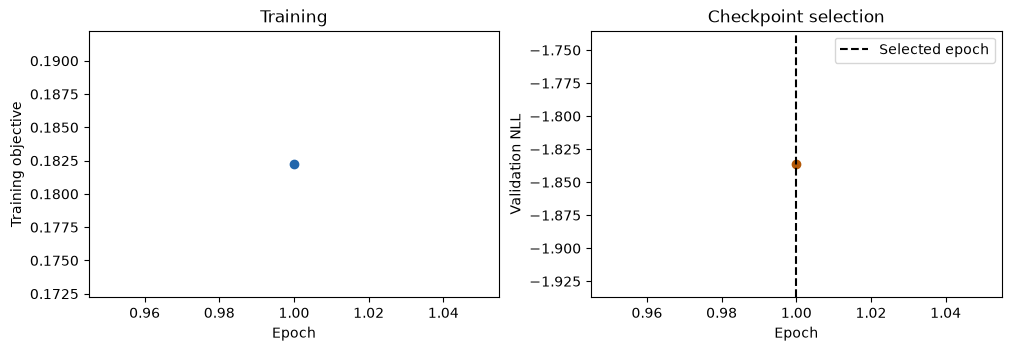

In [6]:
history, best_score, best_state, best_epoch = [], float("inf"), None, None
generator = torch.Generator().manual_seed(SEED)
stale_epochs = 0
for epoch in range(EPOCHS):
    model.train()
    permutation = torch.randperm(len(X_train), generator=generator)
    training_sum, training_count = 0.0, 0
    for batch_index, indices in enumerate(permutation.split(BATCH_SIZE)):
        if MAX_BATCHES and batch_index >= MAX_BATCHES: break
        optimizer.zero_grad(set_to_none=True)
        output = model(X_train[indices])
        loss = criterion(*output, Y_train[indices]) if TASK == "regression" else criterion(output, Y_train[indices], epoch)
        if not torch.isfinite(loss): raise RuntimeError("Nonfinite training loss; inspect data scaling and learning rate")
        loss.backward()
        optimizer.step()
        training_sum += loss.item()*len(indices)
        training_count += len(indices)
    model.eval()
    with torch.no_grad():
        if TASK == "regression":
            mu, nu, alpha, beta = model(X_val)
            pred = torch.distributions.StudentT(2*alpha, mu, torch.sqrt(beta*(1+nu)/(nu*alpha)))
            validation_score = -pred.log_prob(Y_val).mean().item()
        else:
            p = model.predict(X_val)[0]
            validation_score = -torch.sum(Y_val*torch.log(p), dim=1).mean().item()
    history.append({"epoch": epoch+1, "train_objective": training_sum/training_count,
                    "validation_nll": validation_score})
    if validation_score < best_score - 1e-6:
        best_score, best_epoch = validation_score, epoch+1
        best_state = copy.deepcopy(model.state_dict())
        stale_epochs = 0
    else:
        stale_epochs += 1
    if PATIENCE is not None and stale_epochs >= PATIENCE:
        break
if best_state is None: raise RuntimeError("Training did not produce a finite validation score")
model.load_state_dict(best_state)
model.eval()
history = pd.DataFrame(history)
history.to_csv(OUTPUT_DIR/"training_history.csv", index=False)
print(f"Selected epoch {best_epoch} using validation NLL only.")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
axes[0].plot(history.epoch, history.train_objective, marker="o", color="#2166ac")
axes[0].set(xlabel="Epoch", ylabel="Training objective", title="Training")
axes[1].plot(history.epoch, history.validation_nll, marker="o", color="#b35806")
axes[1].axvline(best_epoch, color="black", linestyle="--", label="Selected epoch")
axes[1].set(xlabel="Epoch", ylabel="Validation NLL", title="Checkpoint selection")
axes[1].legend()
plt.show()

## 7. Evaluate the untouched test set
For regression, intervals, PIT and NLL use the Student-t predictive distribution, in original target units. Multi-target metrics are marginal, not a joint covariance model. For classification, the Brier score sums squared errors across classes before averaging examples; entropy, DST mass and variance are distinct quantities.

In [7]:
# The model and all preprocessing are now frozen. Evaluate test outcomes here.
if TASK == "regression":
    parameters = tuple(value.detach().cpu().numpy()
                       for value in model.predict(X_test, return_uncertainties=False))
    evaluation = evaluate_nig(y_all[test_idx], parameters, y_scaler=y_scaler)
    metrics = evaluation["metrics"].copy()
    metrics.index = TARGET_COLUMNS
    display(metrics)
    display(evaluation["coverage"])
    metrics.to_csv(OUTPUT_DIR/"test_metrics.csv", index_label="target")
    evaluation["coverage"].to_csv(OUTPUT_DIR/"test_coverage.csv", index=False)
    prediction_table = pd.DataFrame({"row_position": test_idx})
    lower, upper = evaluation["intervals"][0.9]
    for j, name in enumerate(TARGET_COLUMNS):
        prediction_table[f"{name}_truth"] = y_all[test_idx, j]
        prediction_table[f"{name}_mean"] = evaluation["mean"][:, j]
        prediction_table[f"{name}_aleatoric_variance"] = evaluation["aleatoric"][:, j]
        prediction_table[f"{name}_epistemic_variance"] = evaluation["epistemic"][:, j]
        prediction_table[f"{name}_lower90"] = lower[:, j]
        prediction_table[f"{name}_upper90"] = upper[:, j]
else:
    probability, dst_mass, aleatoric, epistemic = [
        value.detach().cpu().numpy() for value in model.predict(X_test)]
    test_labels = label_encoder.transform(y_all[test_idx])
    evaluation = evaluate_classifier(test_labels, probability)
    display(pd.Series(evaluation["metrics"], name="test").to_frame())
    pd.Series(evaluation["metrics"]).to_csv(OUTPUT_DIR/"test_metrics.csv", header=["value"])
    prediction_table = pd.DataFrame({"row_position": test_idx, "truth": y_all[test_idx],
        "prediction": label_encoder.inverse_transform(probability.argmax(axis=1)),
        "dst_uncertainty_mass": dst_mass[:, 0],
        "aleatoric_variance_trace": aleatoric.sum(axis=1),
        "epistemic_variance_trace": epistemic.sum(axis=1)})
    for j, name in enumerate(label_encoder.classes_):
        prediction_table[f"p_{name}"] = probability[:, j]
if plot_times is not None:
    # Positional indexing keeps timestamps aligned with the exact prediction rows.
    prediction_table["plot_time"] = plot_times.iloc[test_idx].to_numpy()
prediction_table.to_csv(OUTPUT_DIR/"test_predictions.csv", index=False)

,mae,rmse,r2,nll
friction_velocity:surface:m_s-1,0.040599,0.05654,0.874515,-1.419262


,target,nominal,observed,mean_width
0,0,0.50,0.692787,0.096749
1,0,0.80,0.960442,0.217178
2,0,0.90,0.984800,0.326966
3,0,0.95,0.995185,0.466472


## 8. Visualise test performance and uncertainty
Calibration is an empirical property; a correct law-of-total-variance calculation does not imply calibrated predictions. Vertical interval bars are predictive intervals for observations, not confidence intervals for a fitted mean. The time panel uses the original held-out timestamps; independent bars and markers never imply continuity across gaps or between different stations/subjects. Its displayed time window affects the figure only: metrics use every test row. With no timestamp column, the horizontal axis is the actual predicted target value, not an observation number or rank.

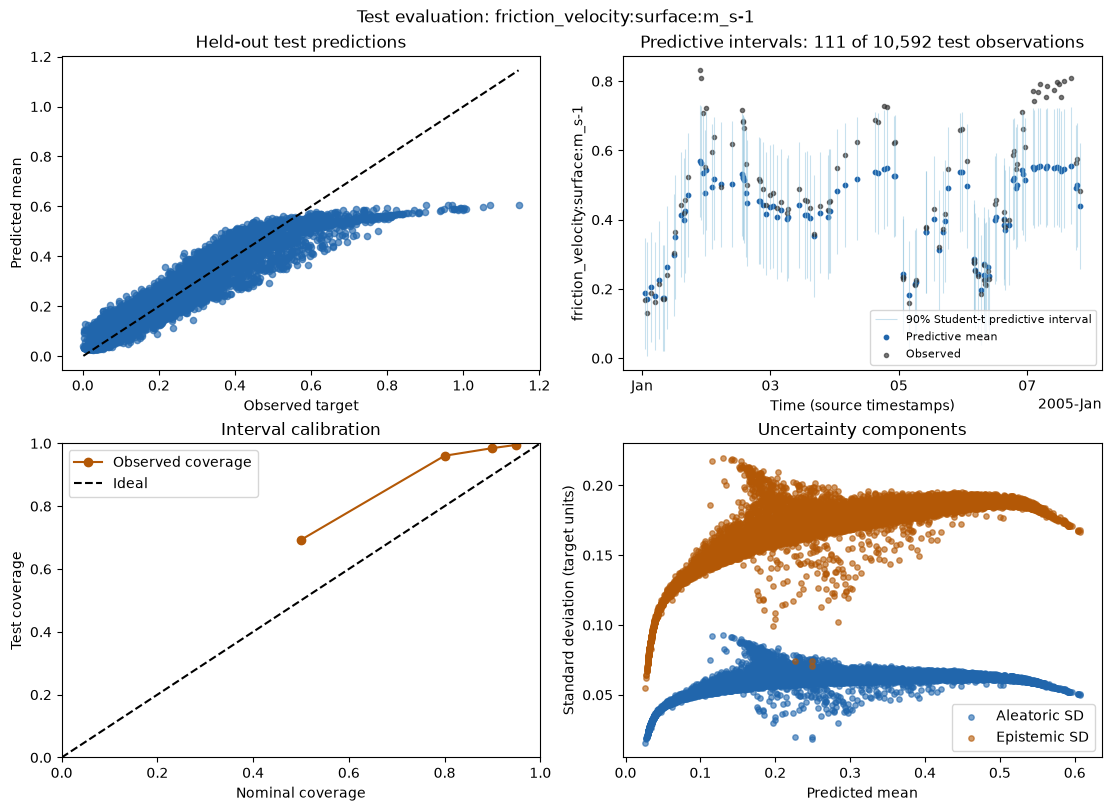

In [8]:
if TASK == "regression":
    target = 0  # Change to inspect another output; metrics above include every target.
    actual = y_all[test_idx, target]
    predicted = evaluation["mean"][:, target]
    lower, upper = evaluation["intervals"][0.9]
    test_times = None if plot_times is None else plot_times.iloc[test_idx]
    order, coordinates = prediction_display(predicted, test_times, plot_time_window)
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
    axes[0,0].scatter(actual, predicted, s=20, alpha=.65, color="#2166ac")
    lo, hi = min(actual.min(), predicted.min()), max(actual.max(), predicted.max())
    axes[0,0].plot([lo, hi], [lo, hi], "k--")
    axes[0,0].set(xlabel="Observed target", ylabel="Predicted mean", title="Held-out test predictions")
    axes[0,1].vlines(coordinates, lower[order,target], upper[order,target],
                      color="#92c5de", alpha=.5, linewidth=.8, label="90% Student-t predictive interval")
    axes[0,1].scatter(coordinates, predicted[order], s=10, color="#2166ac", label="Predictive mean")
    axes[0,1].scatter(coordinates, actual[order], s=9, color="#333333", alpha=.65, label="Observed")
    if test_times is not None:
        is_datetime = not pd.api.types.is_numeric_dtype(test_times)
        time_basis = "UTC" if is_datetime and test_times.dt.tz is not None else "source timestamps"
        x_label = f"{plot_time_column} ({time_basis})" if is_datetime else f"{plot_time_column} (source time units)"
        if is_datetime:
            locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
            axes[0,1].xaxis.set_major_locator(locator)
            axes[0,1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    else:
        x_label = "Predicted mean (target units)"
    axes[0,1].set(xlabel=x_label, ylabel=TARGET_COLUMNS[target],
                  title=f"Predictive intervals: {len(order):,} of {len(test_idx):,} test observations")
    axes[0,1].legend(fontsize=8)
    calibration = evaluation["coverage"].query("target == @target")
    axes[1,0].plot(calibration.nominal, calibration.observed, "o-", color="#b35806", label="Observed coverage")
    axes[1,0].plot([0,1], [0,1], "k--", label="Ideal")
    axes[1,0].set(xlim=(0,1), ylim=(0,1), xlabel="Nominal coverage", ylabel="Test coverage",
                  title="Interval calibration")
    axes[1,0].legend()
    axes[1,1].scatter(predicted, np.sqrt(evaluation["aleatoric"][:,target]), s=15, alpha=.6,
                      label="Aleatoric SD", color="#2166ac")
    axes[1,1].scatter(predicted, np.sqrt(evaluation["epistemic"][:,target]), s=15, alpha=.6,
                      label="Epistemic SD", color="#b35806")
    axes[1,1].set(xlabel="Predicted mean", ylabel="Standard deviation (target units)",
                  title="Uncertainty components")
    axes[1,1].legend()
    fig.suptitle(f"Test evaluation: {TARGET_COLUMNS[target]}")
else:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    confusion = evaluation["confusion"]
    image = axes[0].imshow(confusion, cmap="Blues")
    for row in range(len(confusion)):
        for col in range(len(confusion)):
            axes[0].text(col,row,str(confusion[row,col]), ha="center", va="center",
                         color="white" if confusion[row,col] > confusion.max()/2 else "black")
    axes[0].set(xticks=range(n_classes), yticks=range(n_classes),
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_,
                xlabel="Predicted class", ylabel="True class", title="Test confusion matrix")
    axes[0].tick_params(axis="x", rotation=35)
    reliability = evaluation["reliability"].query("count > 0")
    axes[1].plot([0,1], [0,1], "k--")
    axes[1].scatter(reliability.confidence, reliability.accuracy,
                     s=30+2*reliability["count"], color="#2166ac")
    axes[1].set(xlim=(0,1), ylim=(0,1), xlabel="Mean predicted confidence", ylabel="Observed accuracy",
                title="Test reliability (size = bin count)")
    correct = probability.argmax(axis=1) == test_labels
    trace_epistemic = epistemic.sum(axis=1)
    if correct.any(): axes[2].hist(trace_epistemic[correct], bins=15, alpha=.6, label="Correct")
    if (~correct).any(): axes[2].hist(trace_epistemic[~correct], bins=15, alpha=.6, label="Incorrect")
    axes[2].set(xlabel="Sum of epistemic class variances", ylabel="Test examples",
                title="Uncertainty and prediction errors")
    axes[2].legend()
fig.savefig(OUTPUT_DIR/"test_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Save everything needed to reproduce the run
Keep these files with the exact package revision and data version. Load preprocessing artifacts only from a trusted source.

In [9]:
torch.save(model.state_dict(), OUTPUT_DIR/"model.pt")
joblib.dump({"x_scaler": x_scaler, "y_scaler": y_scaler, "label_encoder": label_encoder},
            OUTPUT_DIR/"preprocessing.joblib")
metadata = {"task": TASK, "features": FEATURE_COLUMNS, "targets": TARGET_COLUMNS,
            "split_strategy": SPLIT_STRATEGY, "data_path": str(Path(DATA_PATH).resolve()),
            "authors_sample": USING_AUTHORS_SAMPLE,
            "plot": {"time_column": plot_time_column, "time_window": plot_time_window},
            "authors_split_seeds": {"outer": 1000, "inner": 1000, "split_index": 0} if USING_AUTHORS_SAMPLE else None, "author_config": str(config_path.relative_to(ROOT)), "seed": SEED, "best_epoch": best_epoch,
            "model_kwargs": model_kwargs, "torch": torch.__version__, "numpy": np.__version__,
            "training": {"optimizer": "Adam", "learning_rate": LEARNING_RATE,
                "batch_size": BATCH_SIZE, "max_epochs": EPOCHS, "patience": PATIENCE,
                "test_fraction": TEST_FRACTION, "validation_fraction": VALIDATION_FRACTION,
                "group_column": GROUP_COLUMN, "time_column": TIME_COLUMN,
                "regression_loss": "LipschitzMSELoss", "regression_coef": author_config.get("train_loss", {}).get("coef"),
                "classification_loss": "EDLDigammaLoss", "annealing_step": 10, "max_batches": MAX_BATCHES},
            "python": platform.python_version(), "miles_guess": version("miles-guess")}
(OUTPUT_DIR/"metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved model, fitted preprocessing, split assignments, metrics, and test predictions to", OUTPUT_DIR.resolve())

Saved model, fitted preprocessing, split assignments, metrics, and test predictions to /workspace/scratch/d7d34632ac75/miles-guess/notebooks/outputs/custom_dataset_guide


## 10. Predict on new, unlabeled rows

In [10]:
# Restore the saved bundle in a fresh session after importing the classes above.
metadata = json.loads((OUTPUT_DIR/"metadata.json").read_text(encoding="utf-8"))
fitted = joblib.load(OUTPUT_DIR/"preprocessing.joblib")  # Load only your own trusted files.
x_scaler, y_scaler = fitted["x_scaler"], fitted["y_scaler"]
label_encoder = fitted["label_encoder"]
model_class = DNN if metadata["task"] == "regression" else CategoricalDNN
model = model_class(**metadata["model_kwargs"]).to("cpu")
model.load_state_dict(torch.load(OUTPUT_DIR/"model.pt", map_location="cpu", weights_only=True))
model.eval()

# In practice replace this with NEW, unlabeled rows with the same feature columns.
# The first three test input rows are reused here only to demonstrate the interface.
new_frame = frame.iloc[test_idx[:3]][FEATURE_COLUMNS].copy()
new_X = torch.tensor(x_scaler.transform(new_frame.to_numpy(dtype=float)), dtype=torch.float32)
if TASK == "regression":
    mean, aleatoric, epistemic, total = [value.cpu().numpy()
        for value in model.predict(new_X, y_scaler=y_scaler)]
    display(pd.DataFrame(mean, columns=[f"{name}_mean" for name in TARGET_COLUMNS]))
    print("Total predictive variances:", total)
else:
    probabilities = model.predict(new_X)[0].cpu().numpy()
    display(pd.DataFrame(probabilities, columns=label_encoder.classes_))

Total predictive variances: [[0.02101138]
 [0.02390192]
 [0.03696205]]


,friction_velocity:surface:m_s-1_mean
0,0.077478
1,0.119706
2,0.353078


## Next steps for a paper
Repeat the fixed experiment across seeds or scientifically meaningful held-out groups. Report predictive skill and calibration together, state the split rule, and keep test outcomes out of tuning decisions. Large uncertainty can be useful for error screening, but this tutorial does not establish an out-of-distribution detection guarantee.

For ensembles or MC dropout, use the corrected mixture APIs documented in UNCERTAINTY.md. A mixture of Student-t members is not generally a single Student-t: averaging NIG parameters is not a valid way to construct predictive intervals.

## 11. Optional diurnal composite, following Figure 11
For a quantity with a meaningful daily cycle, this plot follows Figure 11 of [Schreck et al. (2024), *Evidential Deep Learning: Enhancing Predictive Uncertainty Estimation for Earth System Science Applications*](https://doi.org/10.1175/AIES-D-23-0093.1), *Artificial Intelligence for the Earth Systems*, 3, e230093: blue triangles for the observed mean, orange squares for the predicted mean, green circles for aleatoric standard deviation, and red pentagons for epistemic standard deviation against **clock time**. It complements the chronological plot above. A diurnal composite is appropriate only when pooling the same time of day across dates answers the scientific question; retain the date plot for nonperiodic data. Disable this optional section when a daily cycle is not meaningful for your dataset. Related stations, subjects, or regimes may need separate composites.

The composite uses **all held-out rows**, with 10-minute clock-time bins. In each bin it plots the observed and predicted means alongside separate uncertainty curves. The uncertainty values are $\sqrt{\operatorname{mean}(\sigma^2_{\rm aleatoric})}$ and $\sqrt{\operatorname{mean}(\sigma^2_{\rm epistemic})}$: root-mean-square conditional standard deviations, computed from the physical-unit variances above. They are not means of standard deviations, standard errors of the bin means, or predictive intervals. They also exclude between-observation variation in predicted means; they are **not** the total uncertainty of a time-bin mixture. Bin counts and the aggregated values are saved for inspection.

Dates without timezone information retain their source clock; timestamps with explicit offsets were normalized to UTC by the plotting configuration above. Numeric elapsed time does not identify a time of day and is skipped. The default uses the authors' Cabauw data and unchanged one-pass regression settings; its plotted values are this notebook's results, **not a reproduction of the paper's trained-model results**. For your data, optionally supply target display names and physical units below; do not infer units from model outputs.


,target,minute_of_day,count,observed_mean,predicted_mean,aleatoric_sd,epistemic_sd
0,friction_velocity:surface:m_s-1,0,79,0.209064,0.211233,0.055163,0.155749
1,friction_velocity:surface:m_s-1,10,57,0.190126,0.205400,0.054964,0.154807
2,friction_velocity:surface:m_s-1,20,69,0.180611,0.198577,0.055034,0.154509
3,friction_velocity:surface:m_s-1,30,75,0.186773,0.191635,0.053790,0.151663
4,friction_velocity:surface:m_s-1,40,84,0.176045,0.195865,0.055815,0.155980


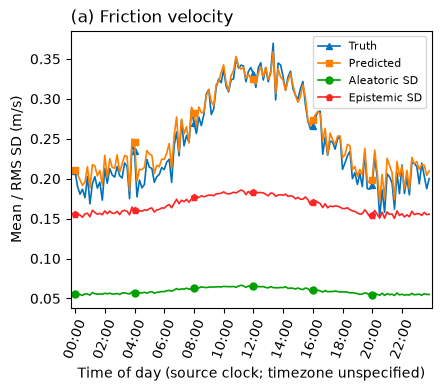

In [11]:
MAKE_DIURNAL_COMPOSITE = True  # Set False when a daily cycle is not scientifically meaningful.
DIURNAL_TARGET_LABELS = None   # Your CSV: optional list of display names, one per TARGET_COLUMNS.
DIURNAL_TARGET_UNITS = None    # Your CSV: optional list of physical units, one per target.

if TASK != "regression":
    print("Diurnal uncertainty composite skipped: this section requires a regression task.")
elif not MAKE_DIURNAL_COMPOSITE:
    print("Diurnal uncertainty composite disabled; use the chronological or predicted-value plot above.")
elif plot_times is None or pd.api.types.is_numeric_dtype(plot_times):
    print("Diurnal uncertainty composite skipped: a date/time column with clock time is required; row positions and numeric elapsed time are not clock time.")
else:
    from mlguess.diurnal import plot_diurnal_uncertainty

    diurnal_labels = DIURNAL_TARGET_LABELS
    diurnal_units = DIURNAL_TARGET_UNITS
    if USING_AUTHORS_SAMPLE:
        if diurnal_labels is None:
            diurnal_labels = ["Friction velocity"]
        if diurnal_units is None:
            diurnal_units = ["m/s"]
    figure11_fig, figure11_axes, figure11_summary = plot_diurnal_uncertainty(
        plot_times.iloc[test_idx], y_all[test_idx], evaluation["mean"],
        evaluation["aleatoric"], evaluation["epistemic"],
        target_names=TARGET_COLUMNS,
        target_labels=diurnal_labels if diurnal_labels is not None else TARGET_COLUMNS,
        units=diurnal_units, bin_minutes=10,
    )
    figure11_fig.savefig(OUTPUT_DIR/"diurnal_uncertainty_figure11.png", dpi=300, bbox_inches="tight")
    figure11_fig.savefig(OUTPUT_DIR/"diurnal_uncertainty_figure11.svg", bbox_inches="tight")
    figure11_summary.to_csv(OUTPUT_DIR/"diurnal_uncertainty_figure11.csv", index=False)
    diurnal_metadata = dict(figure11_summary.attrs,
                            test_observations=len(test_idx), target_names=TARGET_COLUMNS,
                            target_labels=diurnal_labels if diurnal_labels is not None else TARGET_COLUMNS,
                            target_units=diurnal_units, uses_all_test_rows=True)
    (OUTPUT_DIR/"diurnal_uncertainty_figure11.json").write_text(
        json.dumps(diurnal_metadata, indent=2), encoding="utf-8")
    display(figure11_summary.head())
    plt.show()
